<a href="https://colab.research.google.com/github/ManKyCoNguyet/DeepLearning_studyGroup/blob/T11_Tien/Tu%E1%BA%A7n%2011/02_pytorch/CNN/emotion_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Overview
- FER2013 dataset (face images + facial expression)
  - Goal: classifying facial exprression
  - Input: a 48x48 image
  - Output: facial expression (angry, disgust, fear, happy, neutral, sad, and surprise)
- Defining an CNN+MLP
- Training and evaluating an CNN+MLP

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import copy

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

import warnings
warnings.filterwarnings("ignore")

# Kiểm tra GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


# (1) Data

In [2]:
!pip install -q datasets

In [3]:
from datasets import load_dataset

# Load dataset
ds = load_dataset("abhilash88/fer2013-enhanced")
print(ds)

README.md:   0%|          | 0.00/10.8k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  171MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 36.6MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 36.8MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25117 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5380 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5390 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['sample_id', 'image', 'emotion', 'emotion_name', 'pixels', 'usage', 'quality_score', 'brightness', 'contrast', 'sample_weight', 'pixel_mean', 'pixel_std', 'pixel_min', 'pixel_max', 'edge_score', 'focus_score', 'brightness_score'],
        num_rows: 25117
    })
    validation: Dataset({
        features: ['sample_id', 'image', 'emotion', 'emotion_name', 'pixels', 'usage', 'quality_score', 'brightness', 'contrast', 'sample_weight', 'pixel_mean', 'pixel_std', 'pixel_min', 'pixel_max', 'edge_score', 'focus_score', 'brightness_score'],
        num_rows: 5380
    })
    test: Dataset({
        features: ['sample_id', 'image', 'emotion', 'emotion_name', 'pixels', 'usage', 'quality_score', 'brightness', 'contrast', 'sample_weight', 'pixel_mean', 'pixel_std', 'pixel_min', 'pixel_max', 'edge_score', 'focus_score', 'brightness_score'],
        num_rows: 5390
    })
})


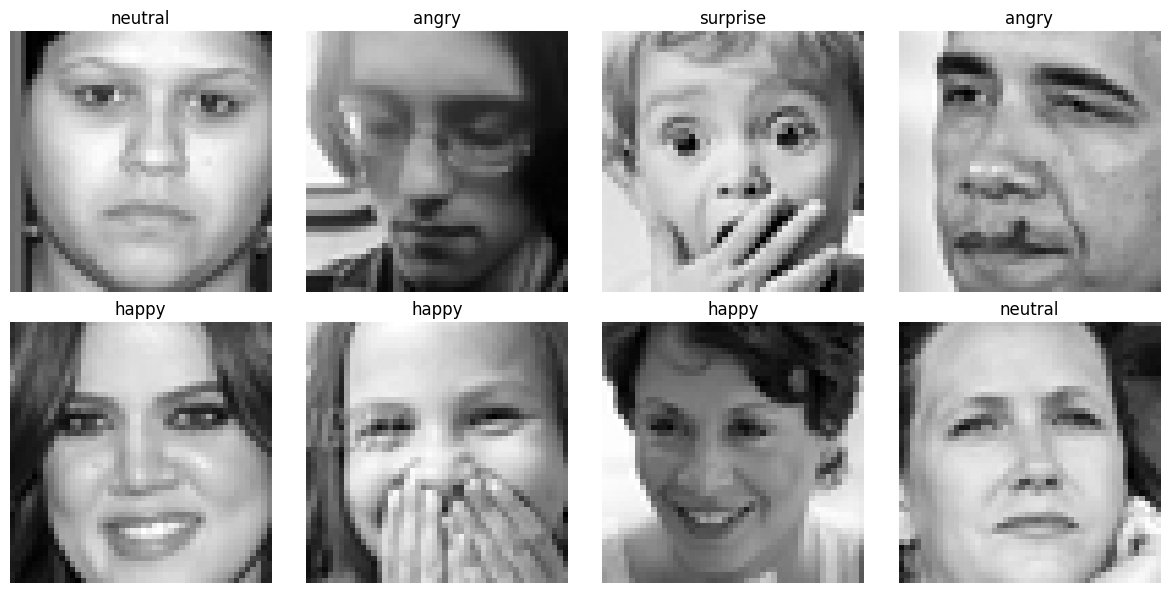

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
axes = axes.flatten()

for i, ax in enumerate(axes):
    sample = ds["train"][i]
    image = sample["image"]
    emotion = sample["emotion_name"]

    ax.imshow(image, cmap="gray")
    ax.set_title(f"{emotion}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [5]:
class FER2013Dataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe
        self.transform = transform

        self.images = [
            np.fromstring(pixel, dtype=np.uint8, sep=' ')
            .reshape(48, 48)
            for pixel in dataframe["pixels"]
        ]

        self.labels = dataframe["emotion"].values

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        image = self.images[idx]
        label = int(self.labels[idx])

        # Chuyển numpy sang PIL
        from PIL import Image
        image = Image.fromarray(image, mode="L")

        if self.transform:
            image = self.transform(image)

        return image, label

In [6]:
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.RandomAffine(
        degrees=0,
        translate=(0.1, 0.1),
        scale=(0.9, 1.1)
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

val_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

# (2) Declare model

In [7]:
class EmoCNN(nn.Module):
    def __init__(self, num_classes: int = 7):
        super().__init__()

        self.features = nn.Sequential(
            # Block 1: 48x48 -> 48x48 -> 46x46 -> pool(2x2) -> 23x23
            nn.Conv2d(in_channels=1, out_channels=64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(in_channels=64, out_channels=64, kernel_size=3, padding=0),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Dropout(p=0.25),
            # Block 2: 23x23 -> 23x23 -> 21x21 -> 21x21 -> 19x19 -> pool(2x2) -> 9x9
            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(in_channels=128, out_channels=128, kernel_size=3, padding=0),
            nn.ReLU(inplace=True),
            nn.Conv2d(in_channels=128, out_channels=218, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(in_channels=218, out_channels=218, kernel_size=3, padding=0),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Dropout(p=0.25),
        )

        # Feature map sau pool2 là (218, 9, 9)
        flattened_dim = 218 * 9 * 9

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=flattened_dim, out_features=1024),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.5),
            nn.Linear(in_features=1024, out_features=num_classes),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.features(x)
        logits = self.classifier(x)
        return logits

In [8]:
if __name__ == "__main__":
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    num_classes = 7  # Khớp với tên lớp gốc fc3_7ways_softmax

    model = EmoCNN(num_classes=num_classes).to(device)
    dummy_input = torch.randn(4, 1, 48, 48, device=device)
    logits = model(dummy_input)
    probs = torch.softmax(logits, dim=1)

    print("Logits shape:", logits.shape)
    print("Probabilities shape:", probs.shape)

Logits shape: torch.Size([4, 7])
Probabilities shape: torch.Size([4, 7])


# (4) Evaluate trained model

In [9]:
def compute_classification_metrics(
    y_true: np.ndarray,
    y_pred: np.ndarray,
    num_classes: int,
) -> dict[str, float | np.ndarray]:
    confusion = np.zeros((num_classes, num_classes), dtype=np.int64)
    for t_val, p_val in zip(y_true, y_pred):
        if 0 <= t_val < num_classes and 0 <= p_val < num_classes:
            confusion[t_val, p_val] += 1

    total = int(confusion.sum())
    correct = int(np.trace(confusion))
    accuracy = (correct / total) if total > 0 else 0.0

    precisions, recalls, f1_scores = [], [], []
    for c in range(num_classes):
        tp = int(confusion[c, c])
        fp = int(confusion[:, c].sum() - tp)
        fn = int(confusion[c, :].sum() - tp)

        precision = (tp / (tp + fp)) if (tp + fp) > 0 else 0.0
        recall = (tp / (tp + fn)) if (tp + fn) > 0 else 0.0
        f1 = (2 * precision * recall / (precision + recall)) if (precision + recall) > 0 else 0.0

        precisions.append(precision)
        recalls.append(recall)
        f1_scores.append(f1)

    return {
        "accuracy": float(accuracy),
        "precision_macro": float(np.mean(precisions)),
        "recall_macro": float(np.mean(recalls)),
        "f1_macro": float(np.mean(f1_scores)),
        "f1_per_class": f1_scores,
        "confusion_matrix": confusion,
    }

def train_one_epoch(
    model: nn.Module,
    dataloader: DataLoader,
    criterion: nn.Module,
    optimizer: torch.optim.Optimizer,
    device: torch.device,
    num_classes: int,
) -> tuple[float, float, float]:
    model.train()  # Bật Dropout(0.25) và Dropout(0.5)
    running_loss = 0.0
    total = 0
    all_targets, all_preds = [], []

    for images, labels in dataloader:
        images = images.to(device, non_blocking=True).float()
        labels = labels.to(device, non_blocking=True).long()

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        running_loss += loss.item() * batch_size
        total += batch_size

        preds = logits.argmax(dim=1)
        all_targets.append(labels.cpu().numpy())
        all_preds.append(preds.cpu().numpy())

    y_true = np.concatenate(all_targets) if all_targets else np.array([], dtype=np.int64)
    y_pred = np.concatenate(all_preds) if all_preds else np.array([], dtype=np.int64)
    metrics = compute_classification_metrics(y_true, y_pred, num_classes=num_classes)

    epoch_loss = running_loss / max(total, 1)
    return epoch_loss, float(metrics["accuracy"]), float(metrics["f1_macro"])


@torch.no_grad()
def evaluate_emo_cnn(
    model: nn.Module,
    dataloader: DataLoader,
    criterion: nn.Module,
    device: torch.device,
    num_classes: int,
) -> dict[str, float | list[float] | np.ndarray]:
    model.eval()  # Tắt Dropout
    running_loss = 0.0
    total = 0
    all_targets, all_preds = [], []

    for images, labels in dataloader:
        images = images.to(device, non_blocking=True).float()
        labels = labels.to(device, non_blocking=True).long()

        logits = model(images)
        loss = criterion(logits, labels)

        batch_size = labels.size(0)
        running_loss += loss.item() * batch_size
        total += batch_size

        preds = logits.argmax(dim=1)
        all_targets.append(labels.cpu().numpy())
        all_preds.append(preds.cpu().numpy())

    y_true = np.concatenate(all_targets) if all_targets else np.array([], dtype=np.int64)
    y_pred = np.concatenate(all_preds) if all_preds else np.array([], dtype=np.int64)
    metrics = compute_classification_metrics(y_true, y_pred, num_classes=num_classes)
    metrics["loss"] = float(running_loss / max(total, 1))
    return metrics

def fit_emo_cnn(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    num_classes: int = 7,
    epochs: int = 30,
    lr: float = 1e-3,
    weight_decay: float = 1e-4,
    checkpoint_path: str = "checkpoints/best_emo_cnn_48x48.pt",
) -> tuple[nn.Module, dict[str, float | list[float] | np.ndarray]]:
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=3, min_lr=1e-6
    )

    best_f1 = -1.0
    best_state = copy.deepcopy(model.state_dict())
    ckpt_file = Path(checkpoint_path)
    ckpt_file.parent.mkdir(parents=True, exist_ok=True)

    print(f"Huấn luyện EmoCNN (48x48) trên thiết bị: {device} | Số lớp: {num_classes}")
    for epoch in range(1, epochs + 1):
        train_loss, train_acc, train_f1 = train_one_epoch(
            model, train_loader, criterion, optimizer, device, num_classes=num_classes
        )
        val_metrics = evaluate_emo_cnn(
            model, val_loader, criterion, device, num_classes=num_classes
        )

        val_loss = float(val_metrics["loss"])
        val_acc = float(val_metrics["accuracy"])
        val_f1 = float(val_metrics["f1_macro"])
        scheduler.step(val_f1)

        current_lr = optimizer.param_groups[0]["lr"]
        print(
            f"Epoch [{epoch:02d}/{epochs:02d}] | lr={current_lr:.2e} | "
            f"Train Loss: {train_loss:.4f}, Acc: {train_acc * 100:.2f}%, F1: {train_f1 * 100:.2f}% | "
            f"Val Loss: {val_loss:.4f}, Acc: {val_acc * 100:.2f}%, F1: {val_f1 * 100:.2f}%"
        )

        if val_f1 > best_f1:
            best_f1 = val_f1
            best_state = copy.deepcopy(model.state_dict())
            torch.save(
                {
                    "epoch": epoch,
                    "num_classes": num_classes,
                    "model_state_dict": best_state,
                    "val_accuracy": val_acc,
                    "val_f1_macro": val_f1,
                },
                ckpt_file,
            )

    model.load_state_dict(best_state)
    final_metrics = evaluate_emo_cnn(model, val_loader, criterion, device, num_classes=num_classes)

    print("\n=== ĐÁNH GIÁ CUỐI CÙNG (BEST CHECKPOINT) ===")
    print(f"Val Loss      : {float(final_metrics['loss']):.4f}")
    print(f"Val Accuracy  : {float(final_metrics['accuracy']) * 100:.2f}%")
    print(f"Macro F1-Score: {float(final_metrics['f1_macro']) * 100:.2f}%")
    print("F1 từng lớp   :", [round(x * 100, 2) for x in final_metrics["f1_per_class"]])
    print("Confusion Matrix:\n", final_metrics["confusion_matrix"])
    print(f"Đã lưu checkpoint tại: {ckpt_file}")

    return model, final_metrics

In [13]:
train_df = pd.DataFrame(ds["train"])
val_df = pd.DataFrame(ds["validation"])
test_df = pd.DataFrame(ds["test"])

train_dataset = FER2013Dataset(train_df, train_transform)
val_dataset = FER2013Dataset(val_df, val_transform)
test_dataset = FER2013Dataset(test_df, val_transform)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

emo_model = EmoCNN(num_classes=num_classes)
fit_emo_cnn(
    model=emo_model,
    train_loader=train_loader,
    val_loader=val_loader,
    num_classes=num_classes,
    epochs=15,
    lr=1e-3,
)

Huấn luyện EmoCNN (48x48) trên thiết bị: cuda | Số lớp: 7
Epoch [01/15] | lr=1.00e-03 | Train Loss: 1.8054, Acc: 24.70%, F1: 10.44% | Val Loss: 1.7714, Acc: 27.57%, F1: 12.22%
Epoch [02/15] | lr=1.00e-03 | Train Loss: 1.7265, Acc: 29.87%, F1: 19.68% | Val Loss: 1.6198, Acc: 34.91%, F1: 22.52%
Epoch [03/15] | lr=1.00e-03 | Train Loss: 1.5971, Acc: 36.71%, F1: 27.00% | Val Loss: 1.4601, Acc: 42.51%, F1: 28.96%
Epoch [04/15] | lr=1.00e-03 | Train Loss: 1.4713, Acc: 42.43%, F1: 32.41% | Val Loss: 1.3649, Acc: 46.73%, F1: 34.27%
Epoch [05/15] | lr=1.00e-03 | Train Loss: 1.3998, Acc: 45.82%, F1: 35.86% | Val Loss: 1.2834, Acc: 51.06%, F1: 40.58%
Epoch [06/15] | lr=1.00e-03 | Train Loss: 1.3594, Acc: 47.46%, F1: 37.41% | Val Loss: 1.2674, Acc: 51.25%, F1: 40.99%
Epoch [07/15] | lr=1.00e-03 | Train Loss: 1.3284, Acc: 48.75%, F1: 38.93% | Val Loss: 1.2301, Acc: 53.10%, F1: 41.85%
Epoch [08/15] | lr=1.00e-03 | Train Loss: 1.2955, Acc: 50.15%, F1: 40.24% | Val Loss: 1.2056, Acc: 53.90%, F1: 45.39

(EmoCNN(
   (features): Sequential(
     (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
     (1): ReLU(inplace=True)
     (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
     (3): ReLU(inplace=True)
     (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
     (5): Dropout(p=0.25, inplace=False)
     (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
     (7): ReLU(inplace=True)
     (8): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1))
     (9): ReLU(inplace=True)
     (10): Conv2d(128, 218, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
     (11): ReLU(inplace=True)
     (12): Conv2d(218, 218, kernel_size=(3, 3), stride=(1, 1))
     (13): ReLU(inplace=True)
     (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
     (15): Dropout(p=0.25, inplace=False)
   )
   (classifier): Sequential(
     (0): Flatten(start_dim=1, end_dim=-1)
     (1): Linear(in_features=17658, out_f

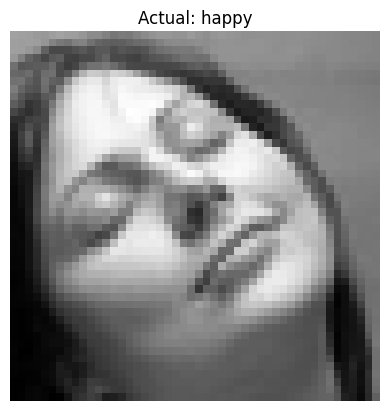

Emotion: sad
Confidence: 29.89%


('sad',
 array([[0.13283594, 0.00139611, 0.079209  , 0.26760715, 0.29894468,
         0.00546194, 0.21454515]], dtype=float32))

In [12]:
emotion_labels = ['angry', 'disgust', 'fear', 'happy', 'sad', 'surprise', 'neutral']

def predict_emotion(image, model):
    model.eval()

    if isinstance(image, np.ndarray):
        from PIL import Image
        image = Image.fromarray(image.astype(np.uint8))

    transform = transforms.Compose([
        transforms.Grayscale(num_output_channels=1),
        transforms.Resize((48, 48)),
        transforms.ToTensor(),
        transforms.Normalize([0.5], [0.5])
    ])

    image = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(image)
        probabilities = torch.softmax(output, dim=1)
        confidence, predicted = torch.max(probabilities, 1)
    emotion = emotion_labels[predicted.item()]

    print("Emotion:", emotion)
    print(f"Confidence: {confidence.item()*100:.2f}%")

    return emotion, probabilities.cpu().numpy()


# Thử nghiệm với một ảnh trong tập test
image, label = test_dataset[10]

plt.imshow(image.squeeze().numpy(), cmap="gray")
plt.title("Actual: " + emotion_labels[label])
plt.axis("off")
plt.show()

# Lưu ý: image đang là tensor đã chuẩn hóa,
# hàm dự đoán nhận ảnh PIL hoặc numpy uint8.
sample_image = test_dataset.images[10]

predict_emotion(sample_image, emo_model)